# **Previsão de Churn (Abandono) em Telecom (Modelo TabKANet)**

# 1. Importando bibliotecas

In [1]:
# Instalação do Efficient-KAN (Implementação rápida do TabKAN) e Optuna
!pip install git+https://github.com/Blealtan/efficient-kan optuna --quiet

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.7/404.7 kB 11.2 MB/s eta 0:00:00


In [2]:
# Importar bibliotecas
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import optuna

# Importação do KAN
from efficient_kan import KAN

from sklearn.metrics import accuracy_score, log_loss, classification_report, mean_squared_error
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_curve
from scipy.stats import ks_2samp
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils import shuffle
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, Rectangle
import seaborn as sns
from copy import deepcopy
import warnings
import io

# Remove warnings:
warnings.filterwarnings("ignore")

# Configuração de Dispositivo (GPU é muito importante para KAN)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("✅ GPU Ativada (CUDA)")
else:
    DEVICE = torch.device("cpu")
    print("⚠️ GPU não detectada (Rodando em CPU - será mais lento)")

✅ GPU Ativada (CUDA)


# 2. Importando banco de dados


In [3]:
# Importar banco de dados
try:
    data = pd.read_csv("customer_churn_telecom_services.csv")
    print("✅ Arquivo carregado do disco.")
except:
    from google.colab import files
    print("Faça upload do arquivo:")
    uploaded = files.upload()
    data = pd.read_csv(io.BytesIO(uploaded[next(iter(uploaded))]))

data.head()

Faça upload do arquivo:


Saving customer_churn_telecom_services.csv to customer_churn_telecom_services.csv


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 3. Dividindo dados

In [4]:
def separa_classe(df_class):
    df_class = shuffle(df_class, random_state=42)

    n = len(df_class)
    train = df_class.iloc[:int(0.5*n)]
    val   = df_class.iloc[int(0.5*n):int(0.75*n)]
    test  = df_class.iloc[int(0.75*n):]

    return train, val, test


def balanceamento(df_maior, df_menor):
    df_menor_bal = df_menor.sample(n=len(df_maior), replace=True, random_state=42)
    return df_menor_bal


def junta_e_mistura(df_x, df_y):
  return shuffle(pd.concat([df_x, df_y]), random_state=42)

In [5]:
# Separar classes
# Classe 0 = Churn no
# Classe 1 = Churn yes
data_cl0 = data[data["Churn"] == "No"]
data_cl1 = data[data["Churn"] == "Yes"]

# Para cada classe, separar treino(50%), validação(25%) e teste(25%) de cada classe
data_cl0_train, data_cl0_val, data_cl0_test = separa_classe(data_cl0)
data_cl1_train, data_cl1_val, data_cl1_test = separa_classe(data_cl1)

# Balancear os dados de treino e validação da classe 2 até ter mesma quantidade que os da classe 1
data_cl1_train = balanceamento(data_cl0_train, data_cl1_train)
data_cl1_val = balanceamento(data_cl0_val, data_cl1_val)


# Embaralhar dados de treino, validação e teste
data_train = junta_e_mistura(data_cl0_train, data_cl1_train)
data_val = junta_e_mistura(data_cl0_val, data_cl1_val)
data_test = junta_e_mistura(data_cl0_test, data_cl1_test)

In [6]:
print("Tamanhos finais:")
print("Treino:", data_train.shape)
print("Validação:", data_val.shape)
print("Teste:", data_test.shape)

Tamanhos finais:
Treino: (5174, 20)
Validação: (2586, 20)
Teste: (1762, 20)


# 4. Tratamento de dados

In [7]:
# ===============================
# Funções de pré-processamento
# ===============================

def fix_inconsistencies(df):
    df = df.copy()

    # 1. Resolver TotalCharges (string -> numeric)
    if "TotalCharges" in df.columns:
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
        df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

    # 2. SeniorCitizen -> Yes/No
    if "SeniorCitizen" in df.columns:
        df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"}).astype("object")

    return df


def treat_missing(df):
    df = df.copy()

    df = df.replace("", np.nan)

    num_cols = df.select_dtypes(include=['number']).columns
    cat_cols = df.select_dtypes(include=['object', 'category']).columns

    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    df[cat_cols] = df[cat_cols].fillna("Missing")

    return df

In [8]:
# 0. Copia banco de dados
tratando_train = data_train.copy()
tratando_val = data_val.copy()
tratando_test = data_test.copy()

In [9]:
# 1. Fix Inconsistências
tratando_train = fix_inconsistencies(tratando_train)
tratando_val = fix_inconsistencies(tratando_val)
tratando_test = fix_inconsistencies(tratando_test)

In [10]:
# 2. Missing
tratando_train = treat_missing(tratando_train)
tratando_val = treat_missing(tratando_val)
tratando_test = treat_missing(tratando_test)

In [11]:
# 3. Transformações
tratando_train["Churn"] = tratando_train["Churn"].map({"Yes": 1, "No": 0})
tratando_val["Churn"] = tratando_val["Churn"].map({"Yes": 1, "No": 0})
tratando_test["Churn"] = tratando_test["Churn"].map({"Yes": 1, "No": 0})

In [12]:
# 4. Separa valores target do resto do datasets:
target = "Churn"

# - Separa valores target de treino, validação e teste:
y_train = tratando_train[target]
y_val   = tratando_val[target]
y_test  = tratando_test[target]

# - Remover os valores target dos datasets para passar ao preprocessor:
tratando_train = tratando_train.drop(columns=[target])
tratando_val = tratando_val.drop(columns=[target])
tratando_test = tratando_test.drop(columns=[target])

In [13]:
# 5. Normalização + Codificação
num_cols = tratando_train.select_dtypes(include=['int64','float64','float32']).columns
cat_cols = tratando_train.select_dtypes(include=['object','category']).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# - Fit no treino (correto!)
preprocessor.fit(tratando_train)

# - Transform no resto
x_train = preprocessor.transform(tratando_train)
x_val   = preprocessor.transform(tratando_val)
x_test  = preprocessor.transform(tratando_test)

# 5. Hiperparametros

In [14]:
# 5. Definição do Modelo TabKANet e Hiperparâmetros

# Classe Wrapper para facilitar o uso do KAN
class TabKANClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, grid_size, spline_order):
        super(TabKANClassifier, self).__init__()

        # Arquitetura KAN: Entrada -> Oculta -> Saída (1 neurônio para binário)
        # O Efficient-KAN aceita uma lista de larguras [in, hidden, out]
        self.kan = KAN([input_dim, hidden_dim, 1], grid_size=grid_size, spline_order=spline_order)

    def forward(self, x):
        # Retorna logits (sem sigmoid, pois usaremos BCEWithLogitsLoss)
        return self.kan(x)

In [15]:
# Espaço de busca dos Hiperparâmetros KAN
# KANs são sensíveis ao Grid Size e Spline Order
grid_size_limits = (3, 10)
spline_order_limits = (3, 5) # Geralmente 3 (cúbico) funciona bem
hidden_size_limits = (16, 128) # Neurônios na camada KAN
lr_limits = (1e-4, 1e-2)
batch_size_limits = (64, 512)
epochs_optuna = 15 # Épocas reduzidas para o Optuna

# 6. Treinamento

In [18]:
def objective(trial):
    # 1. Sugestão de Parâmetros
    grid_size = trial.suggest_int("grid_size", grid_size_limits[0], grid_size_limits[1])
    spline_order = trial.suggest_int("spline_order", spline_order_limits[0], spline_order_limits[1])
    hidden_dim = trial.suggest_int("hidden_dim", hidden_size_limits[0], hidden_size_limits[1])
    lr = trial.suggest_float("lr", lr_limits[0], lr_limits[1], log=True)
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256, 512])

    # 2. Preparar Dados (Tensor PyTorch) - CORREÇÃO DE TIPO AQUI
    # Forçamos dtype=torch.float32 para alinhar com os pesos da rede
    X_train_t = torch.tensor(x_train, dtype=torch.float32).to(DEVICE)
    y_train_t = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1).to(DEVICE)
    X_val_t = torch.tensor(x_val, dtype=torch.float32).to(DEVICE)
    y_val_t = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1).to(DEVICE)

    # Dataset e DataLoader para batch training
    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    # 3. Instanciar Modelo
    model = TabKANClassifier(
        input_dim=x_train.shape[1],
        hidden_dim=hidden_dim,
        grid_size=grid_size,
        spline_order=spline_order
    ).to(DEVICE)

    # Otimizador e Loss
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()

    # 4. Loop de Treino
    for epoch in range(epochs_optuna):
        model.train()
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

    # 5. Avaliação Final (Validação)
    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t)

    return val_loss.item()

In [19]:
# Optuna executando busca
# KANs podem ser um pouco mais lentas que MLPs simples,
# mas Efficient-KAN é bem otimizado.
print("Iniciando otimização do TabKANet...")
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

[I 2025-12-12 17:23:55,024] A new study created in memory with name: no-name-bbbf4beb-16e9-4e9b-aae3-12726777bbc7


Iniciando otimização do TabKANet...


[I 2025-12-12 17:24:04,544] Trial 0 finished with value: 0.5197214484214783 and parameters: {'grid_size': 3, 'spline_order': 5, 'hidden_dim': 82, 'lr': 0.00017086447397341042, 'batch_size': 256}. Best is trial 0 with value: 0.5197214484214783.
[I 2025-12-12 17:24:07,078] Trial 1 finished with value: 0.5054112672805786 and parameters: {'grid_size': 5, 'spline_order': 5, 'hidden_dim': 53, 'lr': 0.0011918141905783157, 'batch_size': 512}. Best is trial 1 with value: 0.5054112672805786.
[I 2025-12-12 17:24:13,965] Trial 2 finished with value: 0.5121489763259888 and parameters: {'grid_size': 9, 'spline_order': 5, 'hidden_dim': 21, 'lr': 0.00012385066965519114, 'batch_size': 64}. Best is trial 1 with value: 0.5054112672805786.
[I 2025-12-12 17:24:20,446] Trial 3 finished with value: 0.6542819738388062 and parameters: {'grid_size': 4, 'spline_order': 4, 'hidden_dim': 37, 'lr': 0.004961419486614845, 'batch_size': 64}. Best is trial 1 with value: 0.5054112672805786.
[I 2025-12-12 17:24:26,431] T

In [20]:
# Resultado do treino com optuna
print("Melhores parâmetros:", study.best_params)
print("Melhor loss:", study.best_value)

Melhores parâmetros: {'grid_size': 10, 'spline_order': 3, 'hidden_dim': 41, 'lr': 0.0006362157121265448, 'batch_size': 128}
Melhor loss: 0.4993934631347656


In [21]:
# Configuração do Modelo Final

best_params = study.best_params

# Recriar o modelo com os melhores parâmetros
final_model = TabKANClassifier(
    input_dim=x_train.shape[1],
    hidden_dim=best_params["hidden_dim"],
    grid_size=best_params["grid_size"],
    spline_order=best_params["spline_order"]
).to(DEVICE)

# Configurações de treino final
final_lr = best_params["lr"]
final_batch = best_params["batch_size"]
final_epochs = 100 # Mais épocas para o treino final

optimizer = optim.AdamW(final_model.parameters(), lr=final_lr, weight_decay=1e-5)
criterion = nn.BCEWithLogitsLoss()

In [22]:
# Treinamento do Modelo Final (Loop completo)

# Dados em Tensor (CORRIGIDO PARA FLOAT32)
X_train_t = torch.tensor(x_train, dtype=torch.float32).to(DEVICE)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1).to(DEVICE)
X_val_t = torch.tensor(x_val, dtype=torch.float32).to(DEVICE)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1).to(DEVICE)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=final_batch, shuffle=True)

print("Iniciando treinamento final do TabKANet...")
train_losses = []
val_losses = []

best_val_loss = float('inf')
best_model_weights = None
patience = 10
patience_counter = 0

for epoch in range(final_epochs):
    final_model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = final_model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Validação
    final_model.eval()
    with torch.no_grad():
        val_out = final_model(X_val_t)
        val_loss = criterion(val_out, y_val_t).item()

    avg_train_loss = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    val_losses.append(val_loss)

    # Early Stopping manual
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = deepcopy(final_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{final_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if patience_counter >= patience:
        print("Early stopping ativado!")
        break

# Carregar o melhor modelo
if best_model_weights:
    final_model.load_state_dict(best_model_weights)
    print("Melhor modelo carregado.")

Iniciando treinamento final do TabKANet...
Epoch 10/100 | Train Loss: 0.4532 | Val Loss: 0.5016
Epoch 20/100 | Train Loss: 0.4175 | Val Loss: 0.5103
Early stopping ativado!
Melhor modelo carregado.


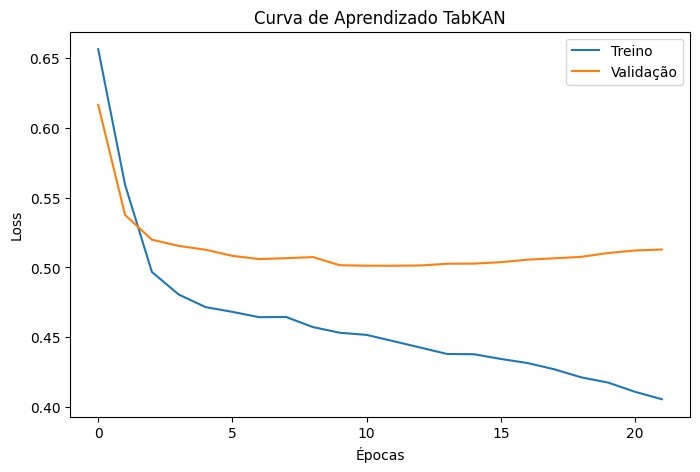

In [23]:
# 7. Análise de desempenho
# Plotar curva de aprendizado
plt.figure(figsize=(8,5))
plt.plot(train_losses, label='Treino')
plt.plot(val_losses, label='Validação')
plt.title("Curva de Aprendizado TabKAN")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.show()

# 7. Analize de desempenho

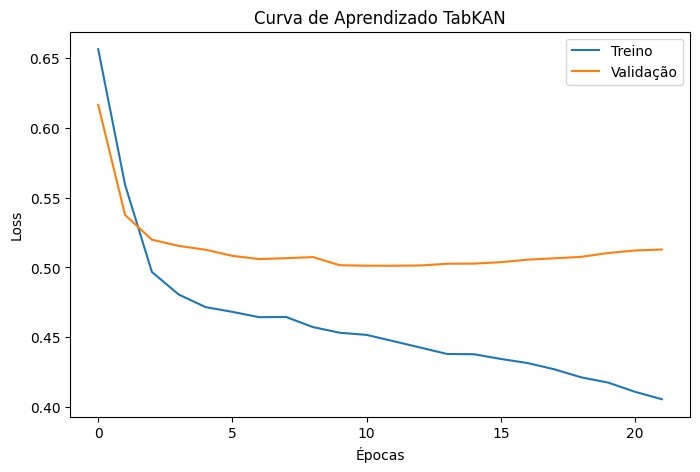

In [28]:
# 7. Análise de desempenho
# Plotar curva de aprendizado
plt.figure(figsize=(8,5))
plt.plot(train_losses, label='Treino')
plt.plot(val_losses, label='Validação')
plt.title("Curva de Aprendizado TabKAN")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [29]:
# === 2. Relatórios de classificação (treino, validação, teste) ===
print("==== CLASSIFICATION REPORT - TREINO ====")
print(classification_report(y_train, y_train_pred))


print("==== CLASSIFICATION REPORT - VALIDAÇÃO ====")
print(classification_report(y_val, y_val_pred))


print("==== CLASSIFICATION REPORT - TESTE ====")
print(classification_report(y_test, y_test_pred))

==== CLASSIFICATION REPORT - TREINO ====
              precision    recall  f1-score   support

           0       0.81      0.75      0.78      2587
           1       0.77      0.82      0.79      2587

    accuracy                           0.79      5174
   macro avg       0.79      0.79      0.79      5174
weighted avg       0.79      0.79      0.79      5174

==== CLASSIFICATION REPORT - VALIDAÇÃO ====
              precision    recall  f1-score   support

           0       0.78      0.73      0.75      1293
           1       0.75      0.80      0.77      1293

    accuracy                           0.76      2586
   macro avg       0.76      0.76      0.76      2586
weighted avg       0.76      0.76      0.76      2586

==== CLASSIFICATION REPORT - TESTE ====
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1294
           1       0.52      0.80      0.63       468

    accuracy                           0.75      1762
   

In [30]:
# === 3. Precision, Recall e F1 ===
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-Score:", f1_score(y_test, y_test_pred))

Precision: 0.5194444444444445
Recall: 0.7991452991452992
F1-Score: 0.6296296296296297


In [32]:
# === 4. MSE (Erro Médio Quadrado) ===
print("MSE Treino:", mean_squared_error(y_train, y_train_pred))
print("MSE Validação:", mean_squared_error(y_val, y_val_pred))
print("MSE Teste:", mean_squared_error(y_test, y_test_pred))

MSE Treino: 0.21414766138384228
MSE Validação: 0.23665893271461716
MSE Teste: 0.24971623155505107


In [34]:
# === 5. Log Loss ===
print("Log Loss Treino:", log_loss(y_train, y_train_proba))
print("Log Loss Validação:", log_loss(y_val, y_val_proba))
print("Log Loss Teste:", log_loss(y_test, y_test_proba))


Log Loss Treino: 0.4442609442829549
Log Loss Validação: 0.5012051132466765
Log Loss Teste: 0.49328667253207337


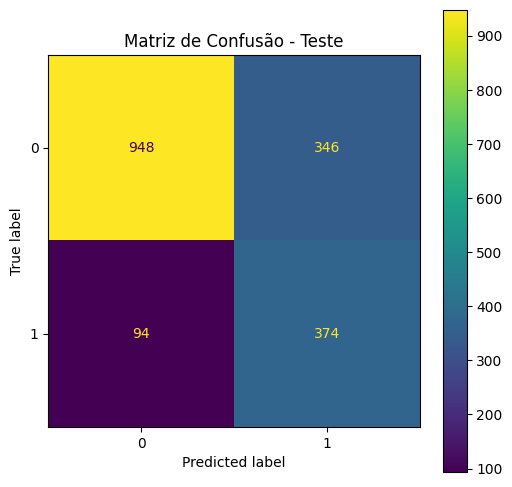

In [35]:
# === 6. Matriz de Confusão ===
fig, ax = plt.subplots(figsize=(6,6))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=ax)
plt.title("Matriz de Confusão - Teste")
plt.show()

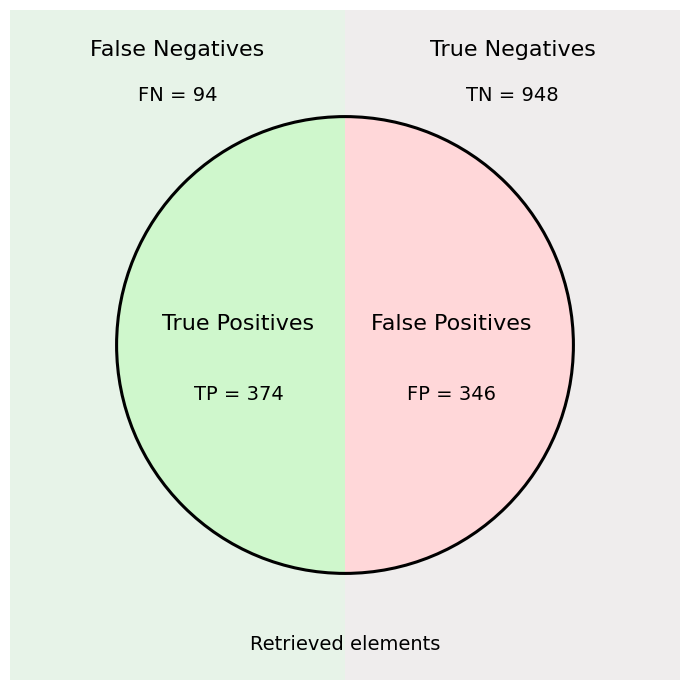

In [36]:
# === 7. Diagrama TN, FP, FN, TP ===
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()

fig, ax = plt.subplots(figsize=(7,7))
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.axis('off')

# ==========================================
# 1) FUNDOS (fora do círculo)
# ==========================================

# Esquerda (False Negatives)
bg_left  = Rectangle((-1.1, -1.1), 1.1, 2.2, facecolor='#e7f3e8', edgecolor='none', zorder=0)

# Direita (True Negatives)
bg_right = Rectangle((0.0, -1.1), 1.1, 2.2, facecolor='#efeded', edgecolor='none', zorder=0)

ax.add_patch(bg_left)
ax.add_patch(bg_right)

# ==========================================
# 2) METADE INTERNA DO CÍRCULO (TP e FP)
# ==========================================

radius = 0.75
center = (0, 0)

# TP = metade esquerda interna
tp_wedge = Wedge(center, radius, 90, 270, facecolor='#cff7cc', edgecolor='none', zorder=1)
# FP = metade direita interna
fp_wedge = Wedge(center, radius, 270, 90, facecolor='#ffd7d9', edgecolor='none', zorder=1)

ax.add_patch(tp_wedge)
ax.add_patch(fp_wedge)

# Contorno do círculo
ax.add_patch(Circle(center, radius, facecolor='none', edgecolor='black', lw=2.2, zorder=3))

# ==========================================
# 3) TEXTOS
# ==========================================

# ---- Regiões externas ----
# False Negatives (topo esquerdo)
ax.text(-0.55, 0.95, "False Negatives", fontsize=16, ha='center')
ax.text(-0.55, 0.80, f"FN = {fn}", fontsize=14, ha='center')

# True Negatives (topo direito)
ax.text(0.55, 0.95, "True Negatives", fontsize=16, ha='center')
ax.text(0.55, 0.80, f"TN = {tn}", fontsize=14, ha='center')

# ---- Regiões internas ----
ax.text(-0.35, 0.05, "True Positives", fontsize=16, ha='center')
ax.text(-0.35, -0.18, f"TP = {tp}", fontsize=14, ha='center')

ax.text( 0.35, 0.05, "False Positives", fontsize=16, ha='center')
ax.text( 0.35, -0.18, f"FP = {fp}", fontsize=14, ha='center')

# Texto inferior
ax.text(0, -1.0, "Retrieved elements", fontsize=14, ha='center')

plt.tight_layout()
plt.show()

In [37]:
# === 8. Teste Kolmogorov-Smirnov (KS) ===
# Probabilidades (y_test_proba) e rótulos verdadeiros (y_test)
probs = y_test_proba
labels = y_test

# Dividir probabilidades por classe
probs_0 = np.sort(probs[labels == 0])
probs_1 = np.sort(probs[labels == 1])

# CDFs (acumuladas)
cdf_0 = np.arange(1, len(probs_0) + 1) / len(probs_0)
cdf_1 = np.arange(1, len(probs_1) + 1) / len(probs_1)

# Emparelhamento por grade comum de thresholds
all_probs = np.sort(np.unique(probs))
cdf0_interp = np.interp(all_probs, probs_0, cdf_0)
cdf1_interp = np.interp(all_probs, probs_1, cdf_1)

# KS por diferença máxima
ks_values = np.abs(cdf1_interp - cdf0_interp)
ks_stat = np.max(ks_values)
best_threshold = all_probs[np.argmax(ks_values)]

print("KS Statistic:", ks_stat)
print("Best threshold:", best_threshold)

KS Statistic: 0.5322050158095044
Best threshold: 0.45910957


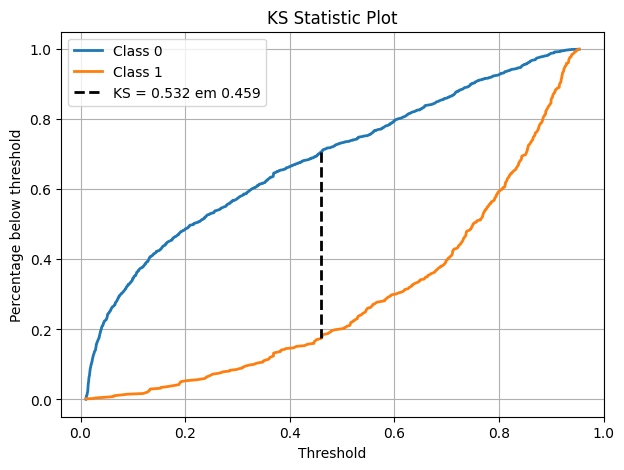

In [38]:
# === 8.5. Gráfico KS ===
plt.figure(figsize=(7, 5))
plt.plot(all_probs, cdf0_interp, label="Class 0", linewidth=2)
plt.plot(all_probs, cdf1_interp, label="Class 1", linewidth=2)

# Linha pontilhada do KS
plt.plot([best_threshold, best_threshold],
         [cdf0_interp[np.argmax(ks_values)], cdf1_interp[np.argmax(ks_values)]],
         'k--', linewidth=2, label=f'KS = {ks_stat:.3f} em {best_threshold:.3f}')

plt.title("KS Statistic Plot")
plt.xlabel("Threshold")
plt.ylabel("Percentage below threshold")

plt.legend()
plt.grid(True)
plt.show()

In [39]:
# === 9. AUROC ===
auc = roc_auc_score(y_test, y_test_proba)
print("AUC (Área sob a ROC):", auc)

AUC (Área sob a ROC): 0.841783742189461


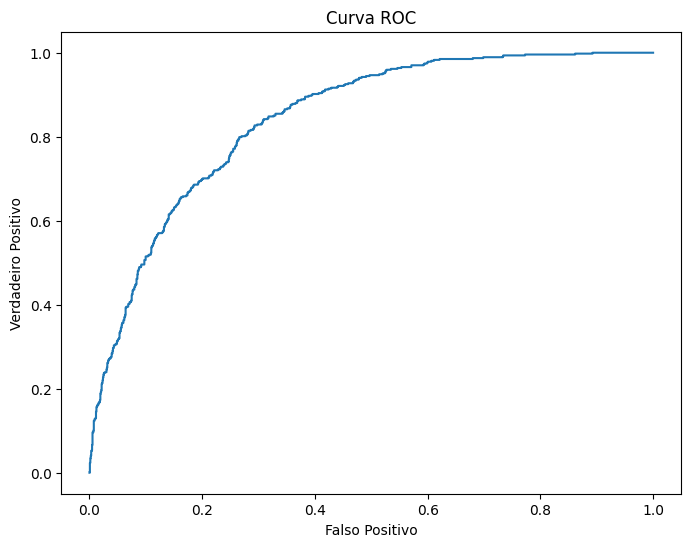

In [40]:
# === 9.5. Curva ROC ===
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr)
plt.title("Curva ROC")
plt.xlabel("Falso Positivo")
plt.ylabel("Verdadeiro Positivo")
plt.show()

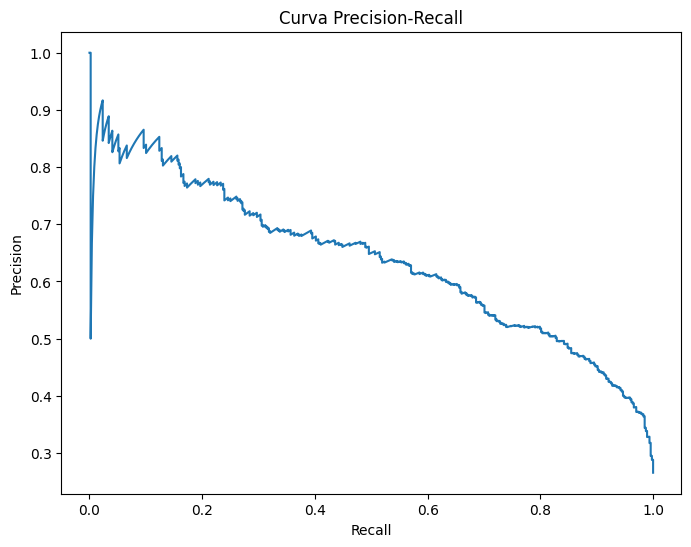

In [41]:
# === 10. Curva Precision-Recall ===
prec, rec, thr = precision_recall_curve(y_test, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(rec, prec)
plt.title("Curva Precision-Recall")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

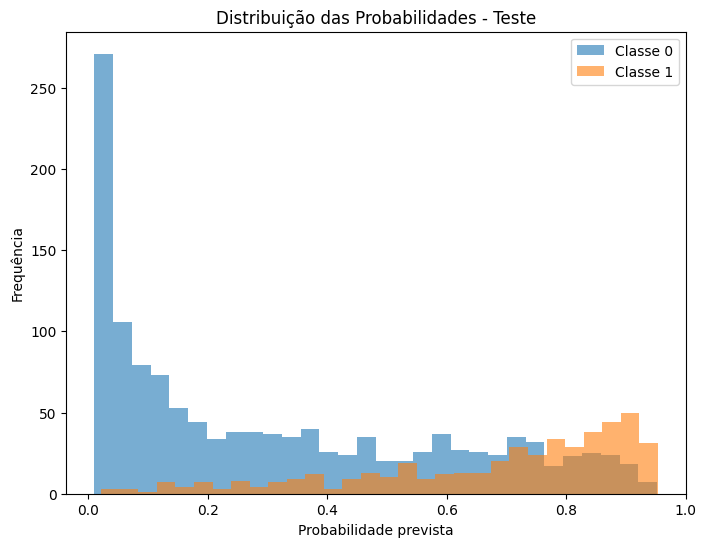

In [42]:
# === 11. Distribuição das probabilidades ===
plt.figure(figsize=(8,6))
plt.hist(y_test_proba[y_test==0], bins=30, alpha=0.6, label='Classe 0')
plt.hist(y_test_proba[y_test==1], bins=30, alpha=0.6, label='Classe 1')
plt.title("Distribuição das Probabilidades - Teste")
plt.xlabel("Probabilidade prevista")
plt.ylabel("Frequência")
plt.legend()
plt.show()